# Installing Dependencies

In [1]:
! pip install -q transformers accelerate bitsandbytes chromadb sentence-transformers datasets gradio torch torchvision Pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 31.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 70.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 88.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.1/72.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.2/180.2 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.6/231.6 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 4.1 MB/s eta 0:00:00
ERROR: pip's depen

In [ ]:
import os
os.makedirs("/kaggle/working/cropquery/", exist_ok = True)

# Writing in Kaggle Working Directory

In [9]:
%%writefile /kaggle/working/cropquery/config.py

import os
os.makedirs("/kaggle/working/cropquery/", exist_ok = True)
# ── Paths ────────────────────────────────────────────────────────────────────
BASE_DIR          = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH        = os.path.join(BASE_DIR, "model.pth")          # phaseC_best.pth
CLASS_NAMES_PATH  = os.path.join(BASE_DIR, "class_names.json")   # list of 64 Crop__Condition labels
CHROMA_DIR = "/kaggle/working/chroma_db"          # persisted vector store

# ── Vision model ─────────────────────────────────────────────────────────────
NUM_CLASSES       = 64
DROPOUT           = 0.4
IMG_SIZE          = 224
CONFIDENCE_GATE   = 85.0   # ResNet hint passed to LLaVA only when conf ≥ this
TOP_K             = 3      # top-k predictions returned by ResNet50

# ── Embedding / RAG ──────────────────────────────────────────────────────────
EMBED_MODEL       = "sentence-transformers/all-MiniLM-L6-v2"
COLLECTION_NAME   = "cropquery_knowledge"
TOP_CHUNKS        = 5
MIN_CROP_CHUNKS   = 2      # fallback to unfiltered retrieval below this

# ── LLaVA ────────────────────────────────────────────────────────────────────
LLAVA_MODEL_ID = "llava-hf/llava-v1.6-mistral-7b-hf"
LLAVA_MAX_TOKENS  = 512
LOAD_IN_4BIT      = True   # BitsAndBytesConfig — keeps it within T4 VRAM

# ── IndicTrans2 ───────────────────────────────────────────────────────────────
INDICTRANS_MODEL  = "ai4bharat/indictrans2-en-indic-1B"
DEFAULT_LANGUAGE  = "hin_Deva"   # Hindi

# Language display name → IndicTrans2 language code
LANGUAGE_CODES = {
    "Hindi":     "hin_Deva",
    "Marathi":   "mar_Deva",
    "Bengali":   "ben_Beng",
    "Telugu":    "tel_Telu",
    "Tamil":     "tam_Taml",
    "Kannada":   "kan_Knda",
    "Gujarati":  "guj_Gujr",
    "Punjabi":   "pan_Guru",
    "Odia":      "ory_Orya",
    "Malayalam": "mal_Mlym",
    "English":   None,           # no translation needed
}

# ── Data sources (for knowledge base builder) ─────────────────────────────────
KAGGLE_WHEAT_RUST_SLUG  = "ivanxavier/wheat-rust-vqa"           # WheatRustVQA
HF_KISAN_DATASET        = "Franklin01/Dataset_prep01"           # Kisan Call Centre


Overwriting /kaggle/working/cropquery/config.py


In [10]:
%%writefile /kaggle/working/cropquery/vision.py

"""
CropQuery — Vision Module
Loads phaseC_best.pth and returns top-k predictions with confidence.
Applies the ≥85% confidence gate used by the RAG + LLaVA stages.
"""

import json
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from typing import List, Tuple, Optional

from .config import (
    MODEL_PATH, CLASS_NAMES_PATH,
    NUM_CLASSES, DROPOUT, IMG_SIZE,
    CONFIDENCE_GATE, TOP_K,
)

# ── Pre-processing (ImageNet stats, matching training) ───────────────────────
_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])


def _build_model(num_classes: int) -> nn.Module:
    """ResNet50 with the same head used during training: Dropout(0.4) → Linear(2048, n)."""
    model = models.resnet50(weights=None)
    model.fc = nn.Sequential(
        nn.Dropout(DROPOUT),
        nn.Linear(2048, num_classes),
    )
    return model


class CropVisionModel:
    """
    Wraps the trained ResNet50 classifier.

    Usage
    -----
    vm = CropVisionModel()
    preds = vm.predict(pil_image)
    # → [("Tomato__Late_Blight", 92.3), ("Tomato__Early_Blight", 5.1), ...]
    """

    def __init__(
        self,
        model_path: str = MODEL_PATH,
        class_names_path: str = CLASS_NAMES_PATH,
        device: Optional[str] = None,
    ):
        self.device = torch.device(
            device if device else ("cuda" if torch.cuda.is_available() else "cpu")
        )

        # ── Load class names ─────────────────────────────────────────────────
        with open(class_names_path) as f:
            raw = json.load(f)
        # Accept either a list or a {idx: name} / {name: idx} dict
        if isinstance(raw, list):
            self.class_names: List[str] = raw
        elif isinstance(raw, dict):
            # Handles both {name: idx} and {idx: name}
            first_key = next(iter(raw))
            if isinstance(raw[first_key], int):
                # {name: idx}
                self.class_names = [None] * len(raw)
                for name, idx in raw.items():
                    self.class_names[idx] = name
            else:
                # {idx: name}  (idx stored as string)
                self.class_names = [raw[str(i)] for i in range(len(raw))]
        else:
            raise ValueError("class_names.json must be a list or dict")

        num_classes = len(self.class_names)

        # ── Load model ───────────────────────────────────────────────────────
        model = _build_model(num_classes)
        state = torch.load(model_path, map_location=self.device)
        # Support raw state_dict or checkpoint dicts
        if "model_state_dict" in state:
            state = state["model_state_dict"]
        elif "state_dict" in state:
            state = state["state_dict"]
        # Strip DataParallel 'module.' prefix if present
        state = {k.replace("module.", ""): v for k, v in state.items()}
        model.load_state_dict(state)
        model.to(self.device)
        model.eval()
        self.model = model
        print(f"[Vision] Loaded ResNet50 ({num_classes} classes) on {self.device}")

    @torch.no_grad()
    def predict(
        self,
        image: Image.Image,
        top_k: int = TOP_K,
    ) -> List[Tuple[str, float]]:
        """
        Returns
        -------
        List of (class_name, confidence_pct) sorted by confidence descending.
        e.g. [("Tomato__Late_Blight", 92.3), ("Tomato__Early_Blight", 5.1), ...]
        """
        if image.mode != "RGB":
            image = image.convert("RGB")
        tensor = _TRANSFORM(image).unsqueeze(0).to(self.device)
        logits = self.model(tensor)
        probs  = torch.softmax(logits, dim=1)[0]
        top    = torch.topk(probs, min(top_k, len(self.class_names)))
        return [
            (self.class_names[idx.item()], round(conf.item() * 100, 2))
            for conf, idx in zip(top.values, top.indices)
        ]

    def gate(self, predictions: List[Tuple[str, float]]) -> Optional[str]:
        """
        Confidence gate: return the top class label only if confidence ≥ 85%.
        Used to decide whether to pass a ResNet hint to LLaVA.
        """
        if predictions and predictions[0][1] >= CONFIDENCE_GATE:
            return predictions[0][0]
        return None

    @staticmethod
    def parse_label(label: str) -> Tuple[str, str]:
        """
        'Tomato__Late_Blight' → ('Tomato', 'Late Blight')
        """
        parts = label.split("__", 1)
        crop  = parts[0].replace("_", " ")
        cond  = parts[1].replace("_", " ") if len(parts) > 1 else "Unknown"
        return crop, cond


Overwriting /kaggle/working/cropquery/vision.py


In [11]:
%%writefile /kaggle/working/cropquery/knowledge_base.py

"""
CropQuery — Knowledge Base Builder
Ingests three data sources into ChromaDB with per-chunk metadata.

Run once to build the vector store; subsequent runs skip if collection
already has documents (use force_rebuild=True to overwrite).

Sources
-------
1. WheatRustVQA (Kaggle)             — image-text Q&A pairs (text only)
2. Kisan Call Centre (HuggingFace)   — real farmer–expert transcripts
3. AgroBench                         — encyclopaedic disease knowledge (built-in)

Usage (Kaggle notebook cell)
-----------------------------
    from cropquery.knowledge_base import KnowledgeBaseBuilder
    builder = KnowledgeBaseBuilder()
    builder.build()
"""

import os
import re
import json
from typing import List, Dict, Any, Optional

import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction

from .config import (
    CHROMA_DIR, COLLECTION_NAME,
    EMBED_MODEL, HF_KISAN_DATASET,
)


# ── AgroBench knowledge (curated subset, always available) ───────────────────
# 30 high-value disease entries covering the 64 model classes.
# Expand this list with the full AgroBench dataset when available.
AGROBENCH_ENTRIES: List[Dict[str, str]] = [
    {
        "crop": "Tomato", "condition": "Late Blight",
        "text": (
            "Tomato Late Blight (Phytophthora infestans). "
            "Symptoms: Water-soaked lesions on leaves that turn brown with a pale green border; "
            "white sporulation on undersides; fruit shows greasy dark patches. "
            "Severity: High — can destroy an entire crop in 7–10 days under humid conditions. "
            "Organic control: Copper-based fungicide (Bordeaux mixture) spray every 7 days. "
            "Chemical control: Mancozeb 75 WP (2g/L) or Metalaxyl + Mancozeb. "
            "Prevention: Avoid overhead irrigation; maintain plant spacing for air circulation; "
            "destroy infected debris; use certified disease-free seeds."
        ),
    },
    {
        "crop": "Tomato", "condition": "Early Blight",
        "text": (
            "Tomato Early Blight (Alternaria solani). "
            "Symptoms: Dark brown spots with concentric rings (target-board pattern) on older leaves; "
            "yellowing around lesions; stem cankers at soil level. "
            "Severity: Moderate — progresses from bottom leaves upward. "
            "Chemical control: Chlorothalonil 75 WP (2g/L) or Mancozeb spray at 10-day intervals. "
            "Organic control: Neem oil (5 mL/L) spray. "
            "Prevention: Crop rotation (avoid Solanaceae for 2–3 years); remove infected leaves promptly; "
            "balanced nitrogen fertilisation (excess N promotes disease)."
        ),
    },
    {
        "crop": "Tomato", "condition": "Bacterial Spot",
        "text": (
            "Tomato Bacterial Spot (Xanthomonas campestris). "
            "Symptoms: Small, water-soaked spots on leaves, stems, and fruit; spots turn dark and "
            "scabby on fruit; defoliation under severe infection. "
            "Chemical control: Copper hydroxide (2g/L) applied preventively; do not apply during rain. "
            "Prevention: Use resistant varieties; avoid working in field when wet; drip irrigation preferred. "
            "Note: Antibiotics (streptomycin) are banned for vegetable use in India."
        ),
    },
    {
        "crop": "Tomato", "condition": "Leaf Mold",
        "text": (
            "Tomato Leaf Mold (Passalora fulva). "
            "Symptoms: Pale yellowish spots on upper leaf surface; olive-green to brown velvety mold "
            "on lower surface. Common in greenhouses and humid regions. "
            "Control: Improve ventilation; reduce humidity below 85%; "
            "Chlorothalonil or Mancozeb spray every 10 days. "
            "Resistant varieties available (Ty-1 gene lines)."
        ),
    },
    {
        "crop": "Potato", "condition": "Late Blight",
        "text": (
            "Potato Late Blight (Phytophthora infestans). "
            "Symptoms: Dark, water-soaked lesions on leaves; white fungal growth on leaf undersides; "
            "tubers show dry rot with reddish-brown discoloration. "
            "High risk when temperature is 10–25°C and humidity >90% for 2+ days. "
            "Chemical control: Metalaxyl + Mancozeb (Ridomil Gold) 2.5g/L; Cymoxanil + Mancozeb. "
            "Spray schedule: Every 7–10 days during risk periods. "
            "Harvest guidance: Stop irrigation 2 weeks before harvest; harvest on dry days."
        ),
    },
    {
        "crop": "Potato", "condition": "Early Blight",
        "text": (
            "Potato Early Blight (Alternaria solani). "
            "Symptoms: Circular dark spots with concentric rings on older leaves; premature defoliation. "
            "Most severe on stressed or nutrient-deficient plants. "
            "Control: Ensure adequate potassium; Mancozeb 75 WP 2g/L spray; Azoxystrobin. "
            "Prevention: Proper plant spacing; hilling to prevent soil splash."
        ),
    },
    {
        "crop": "Corn", "condition": "Common Rust",
        "text": (
            "Corn Common Rust (Puccinia sorghi). "
            "Symptoms: Small, circular to elongated cinnamon-brown pustules on both leaf surfaces; "
            "pustules rupture releasing rusty orange spores. "
            "Severity: Moderate in most seasons; severe in cool and humid conditions. "
            "Control: Propiconazole or Tebuconazole foliar spray at early infection. "
            "Planting: Use resistant hybrids; early planting avoids peak rust season."
        ),
    },
    {
        "crop": "Corn", "condition": "Gray Leaf Spot",
        "text": (
            "Corn Gray Leaf Spot (Cercospora zeae-maydis). "
            "Symptoms: Rectangular, tan-gray lesions with parallel edges running along leaf veins; "
            "lesions coalesce causing large dead areas. Severe in warm humid regions. "
            "Control: Strobilurin fungicides (Azoxystrobin); Triazoles. "
            "Agronomy: Crop rotation with non-host crops; tillage to bury residue reduces inoculum."
        ),
    },
    {
        "crop": "Corn", "condition": "Northern Leaf Blight",
        "text": (
            "Corn Northern Leaf Blight (Exserohilum turcicum). "
            "Symptoms: Long (5–15 cm) cigar-shaped lesions, tan with dark borders; "
            "lesions begin on lower leaves and progress upward; dark spores visible in lesions. "
            "Control: Mancozeb + Carbendazim spray; Propiconazole. "
            "Resistant varieties are the primary management strategy."
        ),
    },
    {
        "crop": "Wheat", "condition": "Leaf Rust",
        "text": (
            "Wheat Leaf Rust (Puccinia triticina). "
            "Symptoms: Small, round to oval orange-red pustules on upper leaf surface; "
            "spores orange-yellow. Spreads rapidly in warm (15–25°C), moist conditions. "
            "Chemical control: Propiconazole 25 EC (1 mL/L) at flag leaf stage; repeat after 15 days. "
            "Mancozeb as preventive. "
            "Importance: One of the most economically damaging wheat diseases in India. "
            "Genetic resistance: Use recommended varieties from ICAR for your agro-climatic zone."
        ),
    },
    {
        "crop": "Wheat", "condition": "Yellow Rust",
        "text": (
            "Wheat Yellow Rust / Stripe Rust (Puccinia striiformis). "
            "Symptoms: Yellow-orange pustules arranged in stripes along leaf veins; "
            "severe on flag leaf. Favoured by cool (10–15°C), moist conditions. "
            "Control: Propiconazole or Tebuconazole spray; apply when 5% plants show symptoms. "
            "India risk zones: North-west plains, hills. Monitor weather advisories from ICAR-IIWBR."
        ),
    },
    {
        "crop": "Rice", "condition": "Leaf Blast",
        "text": (
            "Rice Leaf Blast (Magnaporthe oryzae). "
            "Symptoms: Diamond-shaped lesions with grey centre and brown border on leaves; "
            "neck blast causes panicle collapse (most damaging). "
            "Favoured by excessive nitrogen, humidity >90%, temperature 24–28°C. "
            "Chemical control: Tricyclazole 75 WP (0.6g/L) or Isoprothiolane; apply at early tillering "
            "and again at panicle initiation. "
            "Organic: Pseudomonas fluorescens bioagent spray (10g/L). "
            "Avoid excess urea; use split nitrogen application."
        ),
    },
    {
        "crop": "Rice", "condition": "Brown Spot",
        "text": (
            "Rice Brown Spot (Cochliobolus miyabeanus). "
            "Symptoms: Oval to circular brown spots with yellow halo; severe on potassium-deficient soils. "
            "Often indicates nutritional stress. "
            "Management: Apply potassium (MOP) before planting; Mancozeb 75 WP 2g/L spray. "
            "Seed treatment with Thiram or Carbendazim (2g/kg seed)."
        ),
    },
    {
        "crop": "Grape", "condition": "Black Rot",
        "text": (
            "Grape Black Rot (Guignardia bidwellii). "
            "Symptoms: Tan-brown circular lesions on leaves with dark border; "
            "infected berries turn black and shrivel into mummified 'raisins'. "
            "Critical spray window: Bloom to 3 weeks post-bloom. "
            "Chemical control: Myclobutanil, Mancozeb, or Captan at 10-day intervals. "
            "Sanitation: Remove mummified berries and infected canes during dormant pruning — "
            "primary inoculum source."
        ),
    },
    {
        "crop": "Grape", "condition": "Black Measles",
        "text": (
            "Grape Black Measles / Esca (fungal complex). "
            "Symptoms: Interveinal chlorosis and necrosis in a 'tiger stripe' pattern; "
            "apoplexy (sudden vine collapse) in severe cases; "
            "dark streaking in wood when canes are cut. "
            "Management: No curative chemical treatment available. "
            "Preventive: Protect pruning wounds with fungicide or wound sealant immediately after cutting; "
            "avoid large pruning cuts. Infected vines may persist for years — mark and monitor."
        ),
    },
    {
        "crop": "Apple", "condition": "Apple Scab",
        "text": (
            "Apple Scab (Venturia inaequalis). "
            "Symptoms: Olive-green to brown scabby lesions on leaves and fruit; "
            "defoliation in severe cases; fruit lesions reduce marketability. "
            "Critical infection periods: Spring when leaves are expanding during wet weather. "
            "Control: Captan, Mancozeb, or Myclobutanil at 7–10 day intervals from green tip to post-petal fall. "
            "Scab models (e.g. RIMpro) help time sprays. "
            "Resistant varieties: Use scab-resistant cultivars where available."
        ),
    },
    {
        "crop": "Cashew", "condition": "Anthracnose",
        "text": (
            "Cashew Anthracnose (Colletotrichum gloeosporioides). "
            "Symptoms: Dark brown to black lesions on leaves, young shoots, and nuts; "
            "tip dieback; severe in humid coastal conditions. "
            "Chemical control: Carbendazim 50 WP (1g/L) or Copper oxychloride (3g/L); "
            "3 sprays at 15-day intervals from flushing stage. "
            "Organic: Pseudomonas fluorescens or Trichoderma viride soil drench. "
            "Pruning: Remove and burn affected branches."
        ),
    },
    {
        "crop": "Coffee", "condition": "Leaf Rust",
        "text": (
            "Coffee Leaf Rust (Hemileia vastatrix). "
            "Symptoms: Pale yellow spots on upper leaf surface; orange powdery spore masses "
            "on lower surface; severe defoliation reduces yield next season. "
            "Critical management: First spray at onset of monsoon; "
            "Copper oxychloride 50 WP (3g/L) or Hexaconazole 5 EC (1 mL/L). "
            "4 sprays at 45-day intervals covers the entire monsoon season. "
            "Shade management: Proper shade regulation improves airflow and reduces infection."
        ),
    },
    {
        "crop": "Sugarcane", "condition": "Red Rot",
        "text": (
            "Sugarcane Red Rot (Colletotrichum falcatum). "
            "Symptoms: Reddening of internal stalk tissues with white patches; "
            "leaves yellow from top; sour smell from infected stalks. "
            "Management: Plant disease-free setts from certified nurseries; "
            "treat setts with Carbendazim (1g/L) before planting. "
            "No effective foliar spray once infection is established — rogue out infected plants. "
            "Resistant varieties recommended by ICAR for your state."
        ),
    },
    {
        "crop": "Pea", "condition": "Powdery Mildew",
        "text": (
            "Pea Powdery Mildew (Erysiphe pisi). "
            "Symptoms: White powdery coating on leaves, stems, and pods; "
            "severely affected leaves turn yellow and dry. Late-season disease. "
            "Chemical control: Karathane (Dinocap) 1 mL/L or Wettable Sulphur 3g/L spray; "
            "repeat at 15-day intervals. "
            "Avoid spraying sulphur when temperature >35°C — phytotoxic. "
            "Resistant varieties: Bonneville, Meteor."
        ),
    },
    {
        "crop": "Pumpkin", "condition": "Downy Mildew",
        "text": (
            "Cucurbit Downy Mildew (Pseudoperonospora cubensis). "
            "Symptoms: Angular yellow spots on upper leaf surface limited by veins; "
            "grey-purple sporulation on lower surface; rapid defoliation. "
            "High risk: Humid nights + warm days. "
            "Chemical control: Cymoxanil + Mancozeb (2.5g/L) or Fosetyl-Al at 7-day intervals. "
            "Drip irrigation and mulching reduce humidity at canopy; "
            "avoid overhead irrigation especially in evenings."
        ),
    },
    {
        "crop": "Melon", "condition": "Nitrogen Deficiency",
        "text": (
            "Melon Nitrogen Deficiency. "
            "Symptoms: Pale yellow-green leaves starting from oldest (lower) leaves; "
            "yellowing uniform across entire leaf; stunted growth. "
            "Correction: Top-dress with urea (2%) foliar spray for quick response; "
            "soil application of Ammonium Sulphate or Urea at recommended dose. "
            "Diagnosis tip: Confirm with soil test before heavy N application — "
            "excess N promotes vegetative growth at expense of fruit set and increases disease susceptibility."
        ),
    },
    {
        "crop": "Tomato", "condition": "Spider Mites Two-spotted",
        "text": (
            "Tomato Two-spotted Spider Mite (Tetranychus urticae). "
            "Symptoms: Stippled, bronzed leaves; fine webbing on underside; "
            "severe: defoliation and plant death. Thrives in hot, dry weather. "
            "Miticide control: Abamectin (0.5 mL/L), Spiromesifen, or Fenpyroximate; "
            "rotate modes of action to prevent resistance. "
            "Organic: Neem oil (5 mL/L) + wetting agent; spray on undersides. "
            "Avoid broad-spectrum insecticides that kill natural predators (Phytoseiid mites)."
        ),
    },
    {
        "crop": "Corn", "condition": "Cercospora Leaf Spot",
        "text": (
            "Corn Cercospora Leaf Spot / Gray Leaf Spot (Cercospora zeae-maydis). "
            "Symptoms: Tan to grey rectangular lesions bounded by veins; "
            "lesions expand in humid weather and coalesce into large blighted areas. "
            "Control: Strobilurin + Triazole tank mix (Azoxystrobin + Propiconazole); "
            "apply at VT/R1 stage for maximum economic benefit. "
            "Hybrid selection: Use GLS-tolerant hybrids in endemic areas."
        ),
    },
    {
        "crop": "Potato", "condition": "Virus Y",
        "text": (
            "Potato Virus Y (PVY). "
            "Symptoms: Mosaic or mottling; necrotic spots or streaks on leaves; "
            "stunting; tuber necrosis in severe strains. "
            "Spread: Non-persistently transmitted by aphids (Myzus persicae). "
            "Management: No cure — plant certified seed potato; control aphid vectors with Imidacloprid "
            "or Thiamethoxam soil drench at planting; mineral oil sprays reduce aphid probing. "
            "Rogue out symptomatic plants early to reduce spread."
        ),
    },
    {
        "crop": "Strawberry", "condition": "Leaf Scorch",
        "text": (
            "Strawberry Leaf Scorch (Diplocarpon earlianum). "
            "Symptoms: Small, irregular dark purple spots on upper leaf surface; "
            "spots do not have a defined border (distinguishes from leaf spot); "
            "severe infection causes leaf margins to appear scorched and brown. "
            "Chemical control: Captan or Myclobutanil spray every 10 days after first signs. "
            "Cultural: Remove old leaves at renovation; improve air circulation; "
            "drip irrigation keeps foliage dry."
        ),
    },
    {
        "crop": "Apple", "condition": "Cedar Apple Rust",
        "text": (
            "Apple Cedar-Apple Rust (Gymnosporangium juniperi-virginianae). "
            "Symptoms: Bright orange-yellow spots on upper leaf surface; "
            "orange tube-like structures on lower surface. Requires alternate host (junipers/cedars). "
            "Chemical control: Myclobutanil or Mancozeb from pink bud through first cover sprays (May). "
            "Cultural: Remove nearby juniper hosts within 300m where feasible. "
            "Resistant apple varieties (Enterprise, Redfree) provide best long-term management."
        ),
    },
    {
        "crop": "Pepper", "condition": "Bacterial Spot",
        "text": (
            "Pepper Bacterial Spot (Xanthomonas euvesicatoria). "
            "Symptoms: Small water-soaked spots on leaves becoming brown with yellow halo; "
            "raised, scabby spots on green fruit; severe defoliation exposes fruit to sunscald. "
            "Chemical control: Copper hydroxide (2g/L) preventive sprays from transplanting; "
            "do not apply in hot weather (phytotoxic). "
            "Resistance: Copper resistance is common — rotate with Acibenzolar-S-methyl (SAR inducer). "
            "Use certified disease-free transplants."
        ),
    },
    {
        "crop": "Soybean", "condition": "Frogeye Leaf Spot",
        "text": (
            "Soybean Frogeye Leaf Spot (Cercospora sojina). "
            "Symptoms: Circular spots with brown border and grey-white centre (frog-eye appearance); "
            "seed infection causes bleached, shrivelled pods and reduced germination. "
            "Chemical control: Trifloxystrobin + Tebuconazole at R3 (beginning pod) stage. "
            "Resistance: Some QoI-resistant strains present — use alternate fungicide classes. "
            "Seed treatment: Thiram or Iprodione reduces seed-to-seedling transmission."
        ),
    },
    {
        "crop": "Tomato", "condition": "Mosaic Virus",
        "text": (
            "Tomato Mosaic Virus (ToMV). "
            "Symptoms: Light and dark green mosaic pattern on leaves; leaves may be distorted or fern-like; "
            "stunting; internal browning of fruit (chocolate fruit). "
            "Spread: Seed-borne and mechanically transmitted (tools, hands). NOT aphid-transmitted. "
            "Management: No cure — use resistant varieties (Tm-2 gene); "
            "disinfect tools with 10% bleach or milk solution between plants; "
            "wash hands after handling tobacco (ToMV source); do not transplant symptomatic seedlings."
        ),
    },
    {
        "crop": "Cashew", "condition": "Leaf Miner",
        "text": (
            "Cashew Leaf Miner (Acrocercops syngramma). "
            "Symptoms: Irregular whitish or brownish mines (tunnels) on leaves made by larvae "
            "feeding inside the leaf tissue; affected leaves curl, dry, and drop prematurely; "
            "severe infestations cause significant defoliation and reduced yield. "
            "Severity: Moderate — worst during flushing season when new leaves emerge. "
            "Chemical control: Spray Dimethoate 30 EC (2 mL/L) or Quinalphos 25 EC (2 mL/L) "
            "targeting young flush; 2–3 sprays at 15-day intervals. "
            "Organic control: Neem oil (5 mL/L) spray on new flush deters egg-laying. "
            "Prevention: Monitor new flush emergence; avoid excess nitrogen which promotes "
            "dense soft growth attractive to leaf miners; collect and burn fallen mined leaves."
        ),
    },
]


def _parse_kisan_dataset() -> List[Dict[str, Any]]:
    """
    Download and parse the Kisan Call Centre dataset from HuggingFace.
    Returns list of chunk dicts ready for ChromaDB.
    """
    try:
        from datasets import load_dataset
    except ImportError:
        print("[KB] 'datasets' library not installed — skipping Kisan Call Centre source")
        return []

    print("[KB] Loading Kisan Call Centre dataset from HuggingFace...")
    try:
        ds = load_dataset(HF_KISAN_DATASET, split="train", trust_remote_code=True)
    except Exception as e:
        print(f"[KB] Could not load Kisan dataset: {e}")
        return []

    chunks = []
    for i, row in enumerate(ds):
        # Dataset has varying column names — probe for common ones
        question = row.get("questions") or ""
        answer   = row.get("answers")   or ""
        crop     = "Unknown"  # dataset has no crop column

        if not question or not answer:
            continue

        text = f"Farmer Query: {question}\nExpert Answer: {answer}"
        chunks.append({
            "id":       f"kisan_{i}",
            "text":     text[:1500],   # cap at 1500 chars
            "metadata": {
                "source":     "kisan_call_centre",
                "crop":       str(crop),
                "condition":  "general",
                "chunk_type": "qa_pair",
                "language":   "en",
            },
        })
    print(f"[KB] Kisan Call Centre: {len(chunks)} Q&A pairs loaded")
    return chunks


def _parse_wheat_rust_vqa(vqa_dir: Optional[str] = None) -> List[Dict[str, Any]]:
    """
    Parse WheatRustVQA text Q&A pairs.
    vqa_dir: path to downloaded dataset. If None, attempts Kaggle input path.
    """
    # Try common Kaggle paths
    search_dirs = [
        vqa_dir,
        "/kaggle/input/wheat-rust-vqa",
        "/kaggle/input/datasets/wheat-rust-vqa",
    ]
    qa_path = None
    for d in search_dirs:
        if d and os.path.isdir(d):
            for fname in ["qa_pairs.json", "annotations.json", "data.json", "train.json"]:
                candidate = os.path.join(d, fname)
                if os.path.exists(candidate):
                    qa_path = candidate
                    break
        if qa_path:
            break

    if not qa_path:
        print("[KB] WheatRustVQA not found — skipping. Download from Kaggle and pass vqa_dir.")
        return []

    with open(qa_path) as f:
        data = json.load(f)

    chunks = []
    items = data if isinstance(data, list) else data.get("annotations", data.get("data", []))
    for i, item in enumerate(items):
        q = item.get("question", "")
        a = item.get("answer", "")
        if not q or not a:
            continue
        text = f"Q: {q}\nA: {a}"
        chunks.append({
            "id":       f"wheat_vqa_{i}",
            "text":     text[:1000],
            "metadata": {
                "source":     "wheat_rust_vqa",
                "crop":       "Wheat",
                "condition":  "rust",
                "chunk_type": "qa_pair",
                "language":   "en",
            },
        })
    print(f"[KB] WheatRustVQA: {len(chunks)} Q&A pairs loaded")
    return chunks


def _build_agrobench_chunks() -> List[Dict[str, Any]]:
    """Convert built-in AgroBench entries to ChromaDB chunk format."""
    chunks = []
    for i, entry in enumerate(AGROBENCH_ENTRIES):
        chunks.append({
            "id":       f"agrobench_{i}",
            "text":     entry["text"],
            "metadata": {
                "source":     "agrobench",
                "crop":       entry["crop"],
                "condition":  entry["condition"],
                "chunk_type": "disease_entry",
                "language":   "en",
            },
        })
    print(f"[KB] AgroBench: {len(chunks)} disease entries loaded")
    return chunks


class KnowledgeBaseBuilder:
    """
    Builds and manages the ChromaDB vector store for CropQuery.

    Parameters
    ----------
    chroma_dir : str
        Directory to persist the ChromaDB collection.
    embed_model : str
        SentenceTransformer model ID.
    """

    def __init__(
        self,
        chroma_dir: str = CHROMA_DIR,
        embed_model: str = EMBED_MODEL,
    ):
        os.makedirs(chroma_dir, exist_ok=True)
        self.client = chromadb.PersistentClient(path=chroma_dir)
        self.ef = SentenceTransformerEmbeddingFunction(model_name=embed_model)
        self.collection = self.client.get_or_create_collection(
            name=COLLECTION_NAME,
            embedding_function=self.ef,
            metadata={"hnsw:space": "cosine"},
        )

    def build(
        self,
        force_rebuild: bool = False,
        vqa_dir: Optional[str] = None,
        batch_size: int = 64,
    ) -> int:
        """
        Build the knowledge base from all three sources.

        Parameters
        ----------
        force_rebuild : bool
            If True, delete the collection and rebuild from scratch.
        vqa_dir : str, optional
            Path to WheatRustVQA dataset directory.
        batch_size : int
            Upsert batch size for ChromaDB.

        Returns
        -------
        Total number of documents in collection after build.
        """
        if force_rebuild:
            print("[KB] Rebuilding from scratch...")
            self.client.delete_collection(COLLECTION_NAME)
            self.collection = self.client.get_or_create_collection(
                name=COLLECTION_NAME,
                embedding_function=self.ef,
                metadata={"hnsw:space": "cosine"},
            )
        elif self.collection.count() > 0:
            print(f"[KB] Collection already has {self.collection.count()} docs. "
                  f"Pass force_rebuild=True to overwrite.")
            return self.collection.count()

        # Gather all chunks
        all_chunks: List[Dict[str, Any]] = []
        all_chunks.extend(_build_agrobench_chunks())
        all_chunks.extend(_parse_kisan_dataset())
        all_chunks.extend(_parse_wheat_rust_vqa(vqa_dir=vqa_dir))

        if not all_chunks:
            print("[KB] No chunks to ingest!")
            return 0

        # Deduplicate IDs
        seen_ids = set()
        unique_chunks = []
        for c in all_chunks:
            if c["id"] not in seen_ids:
                seen_ids.add(c["id"])
                unique_chunks.append(c)

        # Upsert in batches
        total = len(unique_chunks)
        print(f"[KB] Upserting {total} chunks into ChromaDB...")
        for start in range(0, total, batch_size):
            batch = unique_chunks[start : start + batch_size]
            self.collection.upsert(
                ids=[c["id"] for c in batch],
                documents=[c["text"] for c in batch],
                metadatas=[c["metadata"] for c in batch],
            )
        print(f"[KB] Done. Collection size: {self.collection.count()} documents")
        return self.collection.count()

    def stats(self) -> Dict[str, Any]:
        """Return collection statistics."""
        count = self.collection.count()
        sources: Dict[str, int] = {}
        # Sample up to 1000 to compute source breakdown
        sample = self.collection.get(limit=min(count, 1000), include=["metadatas"])
        for meta in sample["metadatas"]:
            src = meta.get("source", "unknown")
            sources[src] = sources.get(src, 0) + 1
        return {"total_documents": count, "source_breakdown": sources}


Overwriting /kaggle/working/cropquery/knowledge_base.py


In [12]:
%%writefile /kaggle/working/cropquery/retriever.py

"""
CropQuery — RAG Retriever
Retrieves top-k relevant knowledge chunks for a given crop/condition query.

Logic
-----
1. Primary:  filter by predicted crop, semantic search over farmer question
2. Fallback: if crop returns < MIN_CROP_CHUNKS results, run unfiltered search
"""

from typing import List, Dict, Any, Optional

import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction

from .config import (
    CHROMA_DIR, COLLECTION_NAME,
    EMBED_MODEL, TOP_CHUNKS, MIN_CROP_CHUNKS,
)


class CropRetriever:
    """
    Wraps ChromaDB for RAG retrieval.

    Usage
    -----
    retriever = CropRetriever()
    chunks = retriever.retrieve("Tomato__Late_Blight", "What fungicide should I spray?")
    prompt  = retriever.build_rag_context(chunks)
    """

    def __init__(
        self,
        chroma_dir: str = CHROMA_DIR,
        embed_model: str = EMBED_MODEL,
        top_k: int = TOP_CHUNKS,
        min_crop_chunks: int = MIN_CROP_CHUNKS,
    ):
        self.top_k = top_k
        self.min_crop_chunks = min_crop_chunks

        client = chromadb.PersistentClient(path=chroma_dir)
        ef = SentenceTransformerEmbeddingFunction(model_name=embed_model)
        self.collection = client.get_collection(
            name=COLLECTION_NAME,
            embedding_function=ef,
        )
        print(f"[RAG] Connected to ChromaDB. {self.collection.count()} documents in collection.")

    def retrieve(
        self,
        predicted_class: Optional[str],
        farmer_question: str = "What should I do?",
    ) -> List[Dict[str, Any]]:
        """
        Retrieve top-k relevant chunks.

        Parameters
        ----------
        predicted_class : str, optional
            ResNet50 prediction in 'Crop__Condition' format, e.g. 'Tomato__Late_Blight'.
            If None, runs unfiltered retrieval.
        farmer_question : str
            Free-form question from the farmer.

        Returns
        -------
        List of dicts: {text, metadata, distance}
        """
        query = self._build_query(predicted_class, farmer_question)
        crop  = self._extract_crop(predicted_class)

        results = None

        # ── Crop-filtered retrieval ──────────────────────────────────────────
        if crop:
            try:
                results = self.collection.query(
                    query_texts=[query],
                    n_results=self.top_k,
                    where={"crop": {"$eq": crop}},
                    include=["documents", "metadatas", "distances"],
                )
                n_found = len(results["documents"][0]) if results["documents"] else 0
                if n_found < self.min_crop_chunks:
                    print(f"[RAG] Only {n_found} crop-specific chunks — falling back to unfiltered")
                    results = None   # trigger fallback
            except Exception as e:
                print(f"[RAG] Crop-filtered query failed ({e}) — falling back to unfiltered")
                results = None

        # ── Unfiltered fallback ──────────────────────────────────────────────
        if results is None:
            results = self.collection.query(
                query_texts=[query],
                n_results=self.top_k,
                include=["documents", "metadatas", "distances"],
            )

        return self._parse_results(results)

    # ── Prompt builder ───────────────────────────────────────────────────────

    def build_rag_context(self, chunks: List[Dict[str, Any]]) -> str:
        """
        Format retrieved chunks into the RAG context block injected into the prompt.
        """
        if not chunks:
            return "No specific knowledge retrieved for this disease. Use general agronomy principles."

        lines = ["=== Retrieved Agricultural Knowledge ==="]
        for i, chunk in enumerate(chunks, 1):
            src  = chunk["metadata"].get("source", "unknown")
            crop = chunk["metadata"].get("crop", "")
            cond = chunk["metadata"].get("condition", "")
            label = f"[{i}] Source: {src}"
            if crop and crop != "Unknown":
                label += f" | Crop: {crop}"
            if cond and cond != "general":
                label += f" | Disease: {cond}"
            lines.append(label)
            lines.append(chunk["text"])
            lines.append("")

        return "\n".join(lines)

    # ── Private helpers ──────────────────────────────────────────────────────

    @staticmethod
    def _extract_crop(predicted_class: Optional[str]) -> Optional[str]:
        if not predicted_class:
            return None
        return predicted_class.split("__")[0].replace("_", " ")

    @staticmethod
    def _build_query(predicted_class: Optional[str], farmer_question: str) -> str:
        parts = []
        if predicted_class:
            crop, _, cond = predicted_class.partition("__")
            parts.append(f"{crop.replace('_', ' ')} {cond.replace('_', ' ')} disease symptoms treatment")
        parts.append(farmer_question)
        return " ".join(parts)

    @staticmethod
    def _parse_results(results: Dict[str, Any]) -> List[Dict[str, Any]]:
        chunks = []
        if not results or not results.get("documents"):
            return chunks
        docs  = results["documents"][0]
        metas = results["metadatas"][0]
        dists = results["distances"][0]
        for doc, meta, dist in zip(docs, metas, dists):
            chunks.append({"text": doc, "metadata": meta, "distance": dist})
        return chunks


Overwriting /kaggle/working/cropquery/retriever.py


In [13]:
%%writefile /kaggle/working/cropquery/advisor.py

"""
CropQuery — LLaVA Advisor
Runs LLaVA-1.5-7B in 4-bit quantization.
Image + RAG chunks + optional ResNet50 hint → structured English advice.

VRAM budget on Kaggle T4 (16 GB):
    LLaVA-1.5-7B  4-bit  ≈  8 GB
    ResNet50             ≈  0.1 GB
    Sentence Transformer ≈  0.1 GB
    Headroom             ≈  7.8 GB  ✓
"""

from typing import List, Dict, Any, Optional
from PIL import Image

from .config import (
    LLAVA_MODEL_ID,
    LLAVA_MAX_TOKENS,
    LOAD_IN_4BIT,
    CONFIDENCE_GATE,
)

# ── System prompt template ────────────────────────────────────────────────────
_SYSTEM_PROMPT = """You are CropQuery, an expert agricultural advisor for Indian farmers.
Use ONLY the retrieved agricultural knowledge below to ground your response.
Do NOT fabricate chemical names, dosages, or treatments not mentioned in the context.
Be practical, concise, and compassionate — the farmer may be in distress.

Structure your response in exactly these four sections:
1. **What this is** — disease name, causative agent (fungal/bacterial/viral/nutrient)
2. **How serious** — assess severity from what you see in the image (mild / moderate / severe)
3. **Immediate action** — what to do TODAY (within 24 hours)
4. **7-day plan** — step-by-step actions over the next week

Keep each section to 2–3 sentences. Use simple language."""


def _build_prompt(
    rag_context: str,
    farmer_question: str,
    resnet_hint: Optional[str],
    confidence: Optional[float],
) -> str:
    parts = [_SYSTEM_PROMPT, ""]

    # Pin the diagnosis at the top when confidence is high
    if resnet_hint and confidence and confidence >= CONFIDENCE_GATE:
        crop, condition = resnet_hint.split("__", 1) if "__" in resnet_hint else (resnet_hint, "Unknown")
        crop      = crop.replace("_", " ")
        condition = condition.replace("_", " ")
        parts.append(
            f"CONFIRMED DIAGNOSIS: The AI vision model has identified this with "
            f"{confidence:.1f}% confidence as **{condition}** in **{crop}**. "
            f"Your entire response MUST be about {condition}. Do not discuss any other disease."
        )
        parts.append("")

    parts.append(rag_context)
    parts.append("")
    parts.append(f"Farmer's Question: {farmer_question or 'What should I do about this?'}")
    return "\n".join(parts)


class LLaVAAdvisor:
    """
    Wraps LLaVA-1.5-7B-HF for image-grounded agricultural advice.

    Parameters
    ----------
    model_id : str
        HuggingFace model ID.
    load_in_4bit : bool
        Whether to quantize with BitsAndBytes (required for T4).
    device_map : str
        Device map — 'auto' works for single or multi-GPU.

    Usage
    -----
    advisor = LLaVAAdvisor()
    advice  = advisor.generate(
        image=pil_image,
        rag_context="...",
        farmer_question="What spray should I use?",
        resnet_hint="Tomato__Late_Blight",
        confidence=91.2,
    )
    """

    def __init__(
        self,
        model_id: str = LLAVA_MODEL_ID,
        load_in_4bit: bool = LOAD_IN_4BIT,
        device_map: str = "auto",
    ):
        import torch
        from transformers import (
            LlavaNextProcessor,
            LlavaNextForConditionalGeneration,
            BitsAndBytesConfig,
        )

        print(f"[LLaVA] Loading {model_id} ({'4-bit' if load_in_4bit else 'full precision'})...")

        quant_cfg = None
        if load_in_4bit:
            quant_cfg = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True,
            )

        self.processor = LlavaNextProcessor.from_pretrained(model_id)
        self.model = LlavaNextForConditionalGeneration.from_pretrained(
            model_id,
            quantization_config=quant_cfg,
            device_map=device_map,
            torch_dtype=torch.float16 if not load_in_4bit else None,
            low_cpu_mem_usage=True,
        )
        self.model.eval()
        print("[LLaVA] Model loaded.")

    def generate(
        self,
        image: Image.Image,
        rag_context: str,
        farmer_question: str = "What should I do?",
        resnet_hint: Optional[str] = None,
        confidence: Optional[float] = None,
        max_new_tokens: int = LLAVA_MAX_TOKENS,
    ) -> str:
        """
        Generate agricultural advice conditioned on the image and RAG context.

        Returns
        -------
        str — structured English advice (4 sections)
        """
        import torch

        if image.mode != "RGB":
            image = image.convert("RGB")

        text_prompt = _build_prompt(rag_context, farmer_question, resnet_hint, confidence)

        # LLaVA-1.5 conversation format
        conversation = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": text_prompt},
                ],
            }
        ]
        prompt_text = self.processor.apply_chat_template(
            conversation, add_generation_prompt=True
        )
        inputs = self.processor(
            images=image,
            text=prompt_text,
            return_tensors="pt",
        ).to(self.model.device)

        with torch.no_grad():
            output_ids = self.model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                temperature=1.0,
                repetition_penalty=1.1,
            )

        # Decode only the generated portion (skip input tokens)
        input_len = inputs["input_ids"].shape[1]
        generated = output_ids[0][input_len:]
        advice = self.processor.decode(generated, skip_special_tokens=True).strip()
        return advice


Overwriting /kaggle/working/cropquery/advisor.py


In [ ]:
%%writefile /kaggle/working/cropquery/translator.py

"""
CropQuery — Multilingual Translation
Translates English advice to Indian regional languages using IndicTrans2.

Model: ai4bharat/indictrans2-en-indic-1B
Runs on CPU — no VRAM impact, no API cost.
Handles agricultural vocabulary better than general VLM multilingual output.
"""

from typing import Optional

from .config import INDICTRANS_MODEL, LANGUAGE_CODES, DEFAULT_LANGUAGE


class IndicTranslator:
    """
    Wraps IndicTrans2 for English → Indian language translation.

    The model is loaded lazily on first call to avoid startup overhead
    when running in English-only mode.

    Usage
    -----
    translator = IndicTranslator()
    hindi_text = translator.translate(english_advice, "Hindi")
    """

    def __init__(self, model_id: str = INDICTRANS_MODEL):
        self.model_id = model_id
        self._pipeline = None   # lazy load

    def _load(self):
        """Load IndicTrans2 pipeline on first use."""
        if self._pipeline is not None:
            return
        print(f"[Trans] Loading IndicTrans2 from {self.model_id}...")
        try:
            from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
            import torch

            self._tokenizer = AutoTokenizer.from_pretrained(
                self.model_id, trust_remote_code=True
            )
            self._model = AutoModelForSeq2SeqLM.from_pretrained(
                self.model_id, trust_remote_code=True
            )
            self._model.eval()
            self._device = "cuda" if torch.cuda.is_available() else "cpu"
            self._model.to(self._device)
            self._torch = torch
            print(f"[Trans] IndicTrans2 loaded on {self._device}.")
        except Exception as e:
            print(f"[Trans] WARNING: Could not load IndicTrans2: {e}")
            print("[Trans] Translation will return the original English text.")
            self._pipeline = False   # sentinel: load failed

    def translate(
        self,
        text: str,
        target_language: str = "Hindi",
        src_lang: str = "eng_Latn",
    ) -> str:
        """
        Translate English text to the target Indian language.

        Parameters
        ----------
        text : str
            English text to translate (typically the 4-section advice).
        target_language : str
            Display name matching LANGUAGE_CODES keys, e.g. 'Hindi', 'Telugu'.
        src_lang : str
            IndicTrans2 source language code (always English here).

        Returns
        -------
        str — translated text, or original text if language is English
               or if the model failed to load.
        """
        tgt_code = LANGUAGE_CODES.get(target_language)

        # English — no translation needed
        if tgt_code is None:
            return text

        self._load()

        # Model load failed — return English
        if self._pipeline is False:
            return text

        try:
            return self._run_translation(text, src_lang, tgt_code)
        except Exception as e:
            print(f"[Trans] Translation failed: {e} — returning English")
            return text

    def _run_translation(self, text: str, src: str, tgt: str) -> str:
        """Run the actual IndicTrans2 inference."""
        # IndicTrans2 uses a sentence-level tokenizer with language tags
        inputs = self._tokenizer(
            text,
            src_lang=src,
            tgt_lang=tgt,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512,
        ).to(self._device)

        with self._torch.no_grad():
            output_ids = self._model.generate(
                **inputs,
                num_beams=5,
                max_length=512,
                early_stopping=True,
            )

        translated = self._tokenizer.batch_decode(
            output_ids, skip_special_tokens=True, clean_up_tokenization_spaces=True
        )
        return translated[0].strip() if translated else text

    @staticmethod
    def available_languages() -> list:
        """Return list of supported language display names."""
        return list(LANGUAGE_CODES.keys())

    @staticmethod
    def language_code(display_name: str) -> Optional[str]:
        """Return the IndicTrans2 code for a display name."""
        return LANGUAGE_CODES.get(display_name)


In [ ]:
%%writefile /kaggle/working/cropquery/pipeline.py

"""
CropQuery — Pipeline Orchestrator
Wires all components together into a single callable.

Flow
----
Image
  → ResNet50       → top-3 classes + confidence
  → Confidence gate → hint if conf ≥ 85%, else None
  → ChromaDB RAG   → top-5 relevant chunks
  → LLaVA-1.5-7B  → structured English advice
  → IndicTrans2    → regional language output
"""

from dataclasses import dataclass, field
from typing import List, Optional, Tuple
from PIL import Image

from .config import CONFIDENCE_GATE


@dataclass
class CropQueryResult:
    """Full output of one CropQuery inference."""

    # Vision
    predictions: List[Tuple[str, float]] = field(default_factory=list)
    resnet_hint: Optional[str]           = None

    # Retrieved knowledge
    rag_chunks: list                     = field(default_factory=list)

    # Language output
    english_advice: str                  = ""
    translated_advice: str               = ""
    target_language: str                 = "English"

    # Convenience
    @property
    def top_class(self) -> Optional[str]:
        return self.predictions[0][0] if self.predictions else None

    @property
    def top_confidence(self) -> Optional[float]:
        return self.predictions[0][1] if self.predictions else None

    @property
    def is_high_confidence(self) -> bool:
        return bool(self.top_confidence and self.top_confidence >= CONFIDENCE_GATE)

    @property
    def advice(self) -> str:
        """Return translated advice if available, else English."""
        return self.translated_advice or self.english_advice

    def summary(self) -> str:
        lines = ["── CropQuery Result ──────────────────────────"]
        for cls, conf in self.predictions:
            lines.append(f"  {'★' if conf >= CONFIDENCE_GATE else '·'} {cls}: {conf:.1f}%")
        lines.append(f"  Language: {self.target_language}")
        lines.append("─────────────────────────────────────────────")
        return "\n".join(lines)


class CropQueryPipeline:
    """
    Full CropQuery inference pipeline.

    Parameters
    ----------
    model_path : str
        Path to phaseC_best.pth (ResNet50 weights).
    class_names_path : str
        Path to class_names.json (64-class list).
    skip_llava : bool
        If True, loads only ResNet50 + RAG (useful for testing without VRAM).

    Usage
    -----
    pipeline = CropQueryPipeline(model_path="model.pth", class_names_path="class_names.json")
    result   = pipeline.run(image=pil_img, farmer_question="...", target_language="Hindi")
    print(result.advice)
    """

    def __init__(
        self,
        model_path: str      = "model.pth",
        class_names_path: str = "class_names.json",
        skip_llava: bool     = False,
    ):
        from .vision     import CropVisionModel
        from .retriever  import CropRetriever
        from .translator import IndicTranslator

        print("[Pipeline] Initialising CropQuery...")
        self.vision     = CropVisionModel(model_path=model_path,
                                          class_names_path=class_names_path)
        self.retriever  = CropRetriever()
        self.translator = IndicTranslator()

        self.advisor = None
        if not skip_llava:
            from .advisor import LLaVAAdvisor
            self.advisor = LLaVAAdvisor()

        print("[Pipeline] Ready.")

    def run(
        self,
        image: Image.Image,
        farmer_question: str = "What should I do?",
        target_language: str = "Hindi",
    ) -> CropQueryResult:
        """
        Run full inference on a PIL image.

        Parameters
        ----------
        image : PIL.Image.Image
        farmer_question : str
            Free-form question from the farmer.
        target_language : str
            One of IndicTranslator.available_languages().

        Returns
        -------
        CropQueryResult
        """
        result = CropQueryResult(target_language=target_language)

        # ── Step 1: ResNet50 ─────────────────────────────────────────────────
        result.predictions = self.vision.predict(image)
        result.resnet_hint = self.vision.gate(result.predictions)

        if result.is_high_confidence:
            print(f"[Pipeline] High confidence: {result.top_class} ({result.top_confidence:.1f}%)")
        else:
            top = result.top_class or "Unknown"
            print(f"[Pipeline] Low confidence ({result.top_confidence:.1f}%) — LLaVA reasons from image alone")

        # ── Step 2: RAG retrieval ─────────────────────────────────────────────
        result.rag_chunks = self.retriever.retrieve(
            predicted_class=result.top_class,
            farmer_question=farmer_question,
        )
        rag_context = self.retriever.build_rag_context(result.rag_chunks)
        print(f"[Pipeline] Retrieved {len(result.rag_chunks)} RAG chunks")

        # ── Step 3: LLaVA ────────────────────────────────────────────────────
        if self.advisor:
            result.english_advice = self.advisor.generate(
                image           = image,
                rag_context     = rag_context,
                farmer_question = farmer_question,
                resnet_hint     = result.resnet_hint,
                confidence      = result.top_confidence,
            )
        else:
            # Skip-LLaVA mode — return a RAG-only text summary
            result.english_advice = (
                f"[RAG-only mode — LLaVA not loaded]\n\n"
                f"Top prediction: {result.top_class} ({result.top_confidence:.1f}%)\n\n"
                + rag_context
            )

        # ── Step 4: Translation ───────────────────────────────────────────────
        if target_language != "English":
            result.translated_advice = self.translator.translate(
                result.english_advice, target_language
            )

        print(f"[Pipeline] Done. Advice generated in {target_language}.")
        return result


In [ ]:
%%writefile /kaggle/working/cropquery/app.py

"""
CropQuery — Gradio Demo
Run: python app.py (or execute in Kaggle notebook with `demo.launch(share=True)`)

Features
--------
- Image upload
- Optional farmer question in native script
- Language selector (10 Indian languages + English)
- Disease panel: top-3 predictions with confidence bars
- Advice panel: 4-section structured output in selected language
- Low-confidence fallback: shows top-3 options, asks farmer to confirm
"""
import sys
sys.path.insert(0, "/kaggle/working")

import os
import json
import gradio as gr
from PIL import Image
from typing import Optional

from cropquery import CropQueryPipeline
from cropquery.config import MODEL_PATH, CLASS_NAMES_PATH, CONFIDENCE_GATE
from cropquery.translator import IndicTranslator
from cropquery.vision import CropVisionModel

# ── Load pipeline once at startup ────────────────────────────────────────────
print("Loading CropQuery pipeline...")
pipeline = CropQueryPipeline(
    model_path        = "/kaggle/input/datasets/vitthaljauhari/cropquery-model/phase3_final.pth",
    class_names_path  = "/kaggle/input/datasets/vitthaljauhari/cropquery-model/class_names.json",
    skip_llava        = False,
)
LANGUAGES = IndicTranslator.available_languages()


# ── Core inference function ───────────────────────────────────────────────────
def run_cropquery(
    image: Optional[Image.Image],
    farmer_question: str,
    target_language: str,
    confirmed_class: Optional[str],    # set by user from low-conf dropdown
) -> tuple:
    """
    Returns: (disease_html, advice_text, low_conf_panel_visible, dropdown_choices)
    """
    if image is None:
        return (
            "<p style='color:#888'>Upload an image to start.</p>",
            "",
            gr.update(visible=False),
            gr.update(choices=[], value=None),
        )

    result = pipeline.run(
        image           = image,
        farmer_question = farmer_question or "What should I do?",
        target_language = target_language,
    )

    # ── Disease panel HTML ────────────────────────────────────────────────────
    def _confidence_bar(conf: float) -> str:
        colour = "#2e7d32" if conf >= CONFIDENCE_GATE else "#f57c00" if conf >= 50 else "#c62828"
        return (
            f"<div style='margin-bottom:10px'>"
            f"  <div style='font-weight:600;margin-bottom:3px'>"
            f"    {pred_label(cls)} <span style='color:#888;font-size:13px'>({conf:.1f}%)</span>"
            f"  </div>"
            f"  <div style='background:#e0e0e0;border-radius:4px;height:8px;width:100%'>"
            f"    <div style='background:{colour};border-radius:4px;height:8px;width:{min(conf,100):.0f}%'></div>"
            f"  </div>"
            f"</div>"
        )

    def pred_label(cls: str) -> str:
        crop, cond = CropVisionModel.parse_label(cls)
        return f"{crop} — {cond}"

    bars_html = "".join(_confidence_bar(conf) for cls, conf in result.predictions)
    badge = (
        "<span style='background:#2e7d32;color:white;padding:2px 8px;border-radius:4px;font-size:12px'>HIGH CONFIDENCE</span>"
        if result.is_high_confidence else
        "<span style='background:#f57c00;color:white;padding:2px 8px;border-radius:4px;font-size:12px'>LOW CONFIDENCE</span>"
    )
    disease_html = f"<div>{badge}</div><br>{bars_html}"

    # ── Low-confidence fallback panel ─────────────────────────────────────────
    show_confirm = not result.is_high_confidence
    dropdown_choices = [f"{cls} ({conf:.0f}%)" for cls, conf in result.predictions]

    return (
        disease_html,
        result.advice,
        gr.update(visible=show_confirm),
        gr.update(choices=dropdown_choices, value=dropdown_choices[0] if dropdown_choices else None),
    )


def rerun_with_confirmed(
    image: Optional[Image.Image],
    farmer_question: str,
    target_language: str,
    confirmed_choice: str,
) -> str:
    """Re-run advice generation with a user-confirmed class."""
    if image is None or not confirmed_choice:
        return ""

    # Extract class name from "Crop__Condition (XX%)"
    confirmed_class = confirmed_choice.split(" (")[0]

    from cropquery.retriever import CropRetriever
    from cropquery.advisor   import LLaVAAdvisor
    from cropquery.translator import IndicTranslator

    retriever   = pipeline.retriever
    advisor     = pipeline.advisor
    translator  = pipeline.translator

    rag_chunks  = retriever.retrieve(confirmed_class, farmer_question)
    rag_context = retriever.build_rag_context(rag_chunks)

    if advisor:
        advice = advisor.generate(
            image           = image,
            rag_context     = rag_context,
            farmer_question = farmer_question,
            resnet_hint     = confirmed_class,
            confidence      = 100.0,   # user confirmed — treat as certain
        )
    else:
        advice = f"[RAG-only]\n\n{rag_context}"

    if target_language != "English":
        advice = translator.translate(advice, target_language)

    return advice


# ── Gradio UI ─────────────────────────────────────────────────────────────────
CSS = """
#title { text-align: center; }
#disease-panel { border: 1px solid #e0e0e0; border-radius: 8px; padding: 16px; }
#advice-panel  { background: #f9fbe7; border-radius: 8px; padding: 16px; min-height: 200px; }
#low-conf-box  { background: #fff3e0; border: 1px solid #f57c00; border-radius: 8px; padding: 16px; }
"""

with gr.Blocks(css=CSS, title="CropQuery") as demo:

    gr.HTML("""
    <div id='title'>
        <h1>🌾 CropQuery</h1>
        <p style='color:#555'>AI-Powered Crop Disease Detection & Farmer Advisory · Multilingual</p>
    </div>
    """)

    with gr.Row():
        # ── Left column: inputs ───────────────────────────────────────────────
        with gr.Column(scale=1):
            image_input = gr.Image(
                type="pil", label="📷 Upload leaf / crop image", height=300
            )
            question_input = gr.Textbox(
                label="❓ Your question (optional — in any language)",
                placeholder="What spray should I use? / कौन सी दवाई लगाएं?",
                lines=2,
            )
            language_dropdown = gr.Dropdown(
                choices=LANGUAGES,
                value="Hindi",
                label="🌐 Output Language",
            )
            run_btn = gr.Button("🔍 Analyse", variant="primary", size="lg")

        # ── Right column: outputs ─────────────────────────────────────────────
        with gr.Column(scale=2):
            disease_panel = gr.HTML(
                value="<p style='color:#888'>Upload an image to start.</p>",
                label="Disease Detection",
                elem_id="disease-panel",
            )

            # Low-confidence confirmation panel (hidden by default)
            with gr.Group(visible=False, elem_id="low-conf-box") as low_conf_panel:
                gr.Markdown(
                    "⚠️ **Low confidence** — please confirm which disease this looks like:"
                )
                confirm_dropdown = gr.Dropdown(
                    choices=[], label="Select the correct disease", interactive=True
                )
                confirm_btn = gr.Button("✅ Confirm and get advice", variant="secondary")

            advice_output = gr.Textbox(
                label="📋 Advice",
                lines=15,
                elem_id="advice-panel",
                show_copy_button=True,
            )

    # ── Event wiring ──────────────────────────────────────────────────────────
    run_btn.click(
        fn=run_cropquery,
        inputs=[image_input, question_input, language_dropdown, confirm_dropdown],
        outputs=[disease_panel, advice_output, low_conf_panel, confirm_dropdown],
    )

    confirm_btn.click(
        fn=rerun_with_confirmed,
        inputs=[image_input, question_input, language_dropdown, confirm_dropdown],
        outputs=[advice_output],
    )

    # Example images
    gr.Examples(
        examples=[
            ["examples/tomato_late_blight.jpg", "What spray should I use?", "Hindi"],
            ["examples/wheat_rust.jpg",          "How serious is this?",     "Telugu"],
            ["examples/corn_gray_leaf.jpg",       "",                          "English"],
        ],
        inputs=[image_input, question_input, language_dropdown],
        label="Example Images",
    )

    gr.HTML("""
    <div style='text-align:center;color:#888;margin-top:16px;font-size:12px'>
        ResNet50 (85.42%) · LLaVA-1.5-7B · ChromaDB RAG · IndicTrans2 · PRISM AI
    </div>
    """)


if __name__ == "__main__":
    demo.launch(
        share        = True,    # generates public URL (required in Kaggle)
        server_port  = 7860,
        show_error   = True,
    )


In [ ]:
%%writefile /kaggle/working/cropquery/__init__.py

"""
CropQuery — AI-Powered Crop Disease Detection & Farmer Advisory System

Quick start
-----------
    from cropquery import CropQueryPipeline
    from PIL import Image

    pipeline = CropQueryPipeline(
        model_path       = "model.pth",
        class_names_path = "class_names.json",
    )
    result = pipeline.run(
        image            = Image.open("leaf.jpg"),
        farmer_question  = "What should I spray?",
        target_language  = "Hindi",
    )
    print(result.advice)

Submodules
----------
- cropquery.vision         — ResNet50 classifier
- cropquery.knowledge_base — ChromaDB builder (run once)
- cropquery.retriever      — RAG retrieval
- cropquery.advisor        — LLaVA-1.5-7B advice generation
- cropquery.translator     — IndicTrans2 multilingual output
- cropquery.pipeline       — full orchestrator
"""

from .pipeline       import CropQueryPipeline, CropQueryResult
from .vision         import CropVisionModel
from .retriever      import CropRetriever
from .translator     import IndicTranslator
from .knowledge_base import KnowledgeBaseBuilder
from .advisor        import LLaVAAdvisor
from . import config

__all__ = [
    "CropQueryPipeline",
    "CropQueryResult",
    "CropVisionModel",
    "CropRetriever",
    "IndicTranslator",
    "KnowledgeBaseBuilder",
    "LLaVAAdvisor",
    "config",
]


# Configuring Paths

In [ ]:
import sys
sys.path.insert(0, "/kaggle/working")

MODEL_PATH       = "/kaggle/input/datasets/vitthaljauhari/cropquery-model/phase3_final.pth"
CLASS_NAMES_PATH = "/kaggle/input/datasets/vitthaljauhari/cropquery-model/class_names.json"

os.makedirs("/kaggle/working/chroma_db", exist_ok = True)
CHROMA_DIR       = "/kaggle/working/chroma_db"

import cropquery.config as cfg
cfg.MODEL_PATH       = MODEL_PATH
cfg.CLASS_NAMES_PATH = CLASS_NAMES_PATH
cfg.CHROMA_DIR       = CHROMA_DIR

# Build Knowledge Base

In [32]:
import importlib
import cropquery.knowledge_base
importlib.reload(cropquery.knowledge_base)
from cropquery.knowledge_base import KnowledgeBaseBuilder

builder = KnowledgeBaseBuilder(chroma_dir=CHROMA_DIR)
builder.build(force_rebuild=True)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Franklin01/Dataset_prep01' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


[KB] Rebuilding from scratch...
[KB] AgroBench: 31 disease entries loaded
[KB] Loading Kisan Call Centre dataset from HuggingFace...
[KB] Kisan Call Centre: 178816 Q&A pairs loaded
[KB] WheatRustVQA not found — skipping. Download from Kaggle and pass vqa_dir.
[KB] Upserting 178847 chunks into ChromaDB...
[KB] Done. Collection size: 178847 documents


178847

# Test Model 

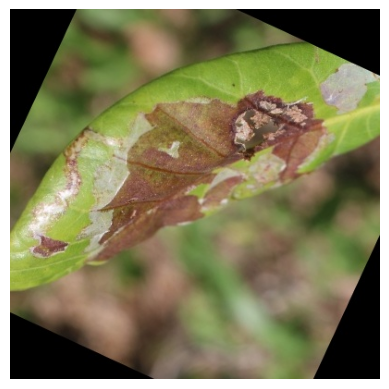

[Vision] Loaded ResNet50 (64 classes) on cuda
Cashew__Leaf_Miner: 93.2%
Cashew__Healthy: 6.7%
Cashew__Anthracnose: 0.1%


In [33]:
from cropquery.vision import CropVisionModel
from PIL import Image
import matplotlib.pyplot as plt
import kagglehub

# Load uploaded test image
ayushbpanchal_path   = kagglehub.dataset_download('ayushbpanchal/cashew-image-dataset')
img_path = "/kaggle/input/datasets/ayushbpanchal/cashew-image-dataset/Cashew/train_set/leaf miner/1004cashew_train_leaf miner.JPG"

img = Image.open(img_path)

# Display image
plt.imshow(img)
plt.axis("off")
plt.show()

# Load model
vm = CropVisionModel(
    model_path=MODEL_PATH,
    class_names_path=CLASS_NAMES_PATH
)

# Predict
preds = vm.predict(img)

# Print predictions
for cls, conf in preds:
    print(f"{cls}: {conf:.1f}%")

# Test RAG 

In [34]:
from cropquery.retriever import CropRetriever

ret    = CropRetriever(chroma_dir=CHROMA_DIR)
chunks = ret.retrieve("Tomato__Late_Blight", "What spray should I use?")

for c in chunks:
    print(c['metadata']['source'])
    print(c['text'][:150])
    print()

[RAG] Connected to ChromaDB. 178847 documents in collection.
agrobench
Tomato Late Blight (Phytophthora infestans). Symptoms: Water-soaked lesions on leaves that turn brown with a pale green border; white sporulation on u

agrobench
Tomato Early Blight (Alternaria solani). Symptoms: Dark brown spots with concentric rings (target-board pattern) on older leaves; yellowing around les

agrobench
Tomato Bacterial Spot (Xanthomonas campestris). Symptoms: Small, water-soaked spots on leaves, stems, and fruit; spots turn dark and scabby on fruit; 

agrobench
Tomato Two-spotted Spider Mite (Tetranychus urticae). Symptoms: Stippled, bronzed leaves; fine webbing on underside; severe: defoliation and plant dea

agrobench
Tomato Leaf Mold (Passalora fulva). Symptoms: Pale yellowish spots on upper leaf surface; olive-green to brown velvety mold on lower surface. Common i



# Run the full pipeline

In [4]:
import os
os.environ["HF_TOKEN"] = "hf_YOUR_TOKEN_HERE"

In [51]:
import torch, gc

# Free everything lingering in GPU memory
gc.collect()
torch.cuda.empty_cache()

print(f"Free VRAM: {torch.cuda.mem_get_info()[0] / 1e9:.2f} GB")

import torch, gc
gc.collect()
torch.cuda.empty_cache()
print(f"GPU 0 free: {torch.cuda.mem_get_info(0)[0] / 1e9:.2f} GB")
print(f"GPU 1 free: {torch.cuda.mem_get_info(1)[0] / 1e9:.2f} GB")

Free VRAM: 5.15 GB
GPU 0 free: 5.15 GB
GPU 1 free: 12.04 GB


In [52]:
del vm
gc.collect()
torch.cuda.empty_cache()

print(f"Free VRAM: {torch.cuda.mem_get_info()[0] / 1e9:.2f} GB")

NameError: name 'vm' is not defined

In [54]:
import torch, gc

# Delete all large objects
try: del pipeline
except: pass
try: del vm
except: pass
try: del builder
except: pass
try: del ret
except: pass

# Clear GPU and CPU memory
gc.collect()
torch.cuda.empty_cache()

print(f"GPU 0 free: {torch.cuda.mem_get_info(0)[0] / 1e9:.2f} GB")
print(f"GPU 1 free: {torch.cuda.mem_get_info(1)[0] / 1e9:.2f} GB")

GPU 0 free: 6.33 GB
GPU 1 free: 15.38 GB


In [5]:
from cropquery import CropQueryPipeline
from PIL import Image

pipeline = CropQueryPipeline(
    model_path       = MODEL_PATH,
    class_names_path = CLASS_NAMES_PATH,
)

img = Image.open("/kaggle/input/datasets/ayushbpanchal/cashew-image-dataset/Cashew/train_set/leaf miner/1001cashew_train_leaf miner.JPG")

result = pipeline.run(
    image           = img,
    farmer_question = "What should I do?",
    target_language = "Hindi",
)

print(result.summary())
print(result.advice)

[Pipeline] Initialising CropQuery...
[Vision] Loaded ResNet50 (64 classes) on cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

dict.TGT.json: 0.00B [00:00, ?B/s]

model.SRC:   0%|          | 0.00/759k [00:00<?, ?B/s]

model.TGT:   0%|          | 0.00/3.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

[Trans] WARNING: Could not load IndicTrans2: No module named 'transformers.onnx'
[Trans] Translation will return the original English text.
[Pipeline] Done. Advice generated in Hindi.
── CropQuery Result ──────────────────────────
  ★ Cashew__Leaf_Miner: 95.4%
  · Cassava__Green_Mottle: 1.8%
  · Cassava__Brown_Streak_Disease: 0.9%
  Language: Hindi
─────────────────────────────────────────────
1. **What this is**: Leaf Miner in Cashew.
2. **How serious**: Moderate.
3. **Immediate action**: Spray Dimethoate 30 EC (2 mL/L) or Quinalphos 25 EC (2 mL/L) targeting young flush.
4. **7-day plan**: Monitor new flush emergence, avoid excess nitrogen, collect and burn fallen mined leaves, repeat sprays at 15-day intervals.


# Launch the Gradio app

In [ ]:
import subprocess, time

proc = subprocess.Popen(
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT
)

time.sleep(15)
for _ in range(40):
    line = proc.stdout.readline().decode()
    print(line, end="")
    if "gradio.live" in line:
        break
    time.sleep(2)